# Лабораторная работа 1

1) Классификация данных методом k ближайших соседей ( kNN)

2) Классификация данных методом опорных векторов (SVM)

3) Построение softmax-классификатора

Вариант 1: задания 1 и 2 на наборе данных CIFAR-10

Вариант 2: задания 1 и 2 на наборе данных MNIST

Вариант 3: задания 1 и 3 на наборе данных CIFAR-10

Вариант 4: задания 1 и 3 на наборе данных MNIST

Лабораторные работы можно выполнять с использованием сервиса Google Colaboratory (https://medium.com/deep-learning-turkey/google-colab-free-gpu-tutorial-e113627b9f5d) или на локальном компьютере.

## 1. Классификация данных методом k ближайших соседей ( kNN)

In [1]:
# Подготовка: папка scripts из репозитория курса
import shutil
import subprocess
from pathlib import Path

if not Path('repo').exists():
    subprocess.run(['git', 'clone', '-q', 'https://github.com/JustHawker/AIT_Course_SamU_2026.git', 'repo'], check=True)
if not Path('scripts').exists():
    shutil.copytree(Path('repo', 'lab_1-2', 'scripts'), 'scripts')

In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scripts.data_utils import load_CIFAR10


%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

1.1 Скачайте данные в соответсвии с заданием.

CIFAR-10 по ссылке https://www.cs.toronto.edu/~kriz/cifar.html
или используйте  команду !bash get_datasets.sh (google colab, local ubuntu)

MNIST
sklearn.datasets import load_digits
digits = load_digits()

In [3]:
# Распаковка CIFAR-10 из архива
import tarfile

cifar_dir = Path('scripts', 'datasets', 'cifar-10-batches-py')
if not cifar_dir.exists():
    with tarfile.open(Path('..', 'cifar-10-python.tar.gz')) as archive:
        if hasattr(tarfile, 'data_filter'):
            archive.extractall(Path('scripts', 'datasets'), filter='data')
        else:
            archive.extractall(Path('scripts', 'datasets'))
print(sorted(p.name for p in cifar_dir.iterdir()))

['batches.meta', 'data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5', 'readme.html', 'test_batch']


In [4]:
cifar10_dir = 'scripts/datasets/cifar-10-batches-py'

try:
   del X_train, y_train
   del X_test, y_test
   print('Clear previously loaded data.')
except:
   pass

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


1.2 Выведите несколько примеров изображений из обучающей выборки для каждого класса.



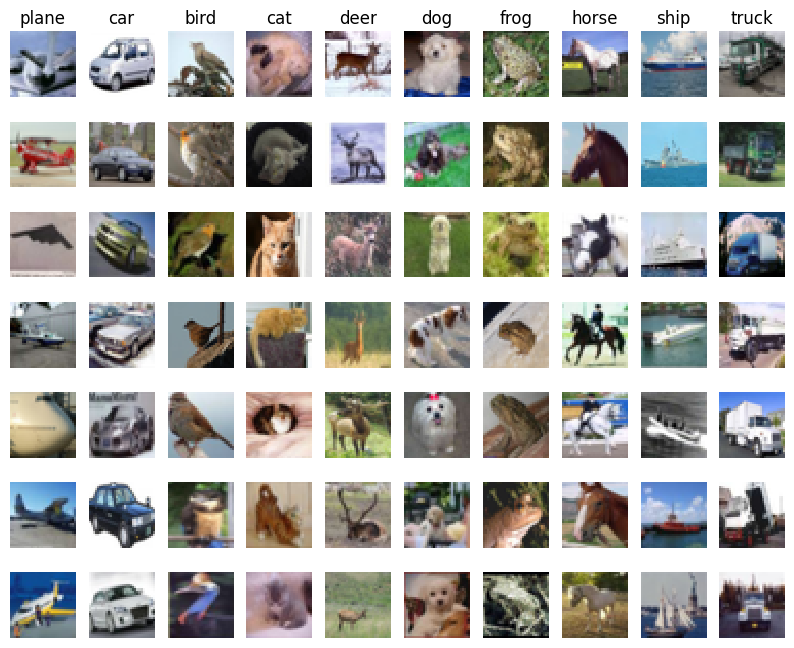

In [5]:
# Примеры изображений: по 7 случайных картинок каждого класса
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
samples_per_class = 7

for y, cls in enumerate(classes):
    idxs = np.random.choice(np.flatnonzero(y_train == y), samples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt.subplot(samples_per_class, len(classes), i * len(classes) + y + 1)
        plt.imshow(X_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

1.3 Разделите данные на обучающу и тестовую выборки (X_train, y_train, X_test, y_test). Преобразуйте каждое изображение в одномерный массив.

In [6]:
# Уменьшенные выборки: 5000 обучающих и 500 тестовых картинок
num_training = 5000
num_test = 500

X_train = X_train[:num_training]
y_train = y_train[:num_training]
X_test = X_test[:num_test]
y_test = y_test[:num_test]

# Каждая картинка 32x32x3 превращается в строку из 3072 чисел
X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

print('X_train:', X_train.shape, 'y_train:', y_train.shape)
print('X_test: ', X_test.shape, 'y_test: ', y_test.shape)

X_train: (5000, 3072) y_train: (5000,)
X_test:  (500, 3072) y_test:  (500,)


1.4 Напишите реализацию классификатора в скрипте /classifiers/k_nearest_neighbor.py и обучите его на сформированной выборке.

In [ ]:
%%writefile scripts/classifiers/k_nearest_neighbor.py
import numpy as np

class KNearestNeighbor(object):
    # Классификатор k ближайших соседей с евклидовым (L2) расстоянием

    def __init__(self):
        pass

    def train(self, X, y):
        # Запоминание обучающих картинок и их меток
        self.X_train = X
        self.y_train = y

    def predict(self, X, k=1, num_loops=0):
        if num_loops == 0:
            dists = self.compute_distances_no_loops(X)
        elif num_loops == 1:
            dists = self.compute_distances_one_loop(X)
        elif num_loops == 2:
            dists = self.compute_distances_two_loops(X)
        else:
            raise ValueError('Invalid value %d for num_loops' % num_loops)
        return self.predict_labels(dists, k=k)

    def compute_distances_two_loops(self, X):
        # Расстояния от каждой тестовой до каждой обучающей картинки, двумя циклами
        num_test = X.shape[0]
        num_train = self.X_train.shape[0]
        dists = np.zeros((num_test, num_train))
        for i in range(num_test):
            for j in range(num_train):
                dists[i, j] = np.sqrt(np.sum((X[i] - self.X_train[j]) ** 2))
        return dists

    def compute_distances_one_loop(self, X):
        # То же самое, но одним циклом: тестовая картинка сравнивается сразу со всеми обучающими
        num_test = X.shape[0]
        num_train = self.X_train.shape[0]
        dists = np.zeros((num_test, num_train))
        for i in range(num_test):
            dists[i, :] = np.sqrt(np.sum((self.X_train - X[i]) ** 2, axis=1))
        return dists

    def compute_distances_no_loops(self, X):
        # То же самое без циклов, по формуле (a - b)^2 = a^2 + b^2 - 2ab
        test_sq = np.sum(X ** 2, axis=1)[:, np.newaxis]
        train_sq = np.sum(self.X_train ** 2, axis=1)[np.newaxis, :]
        cross = X.dot(self.X_train.T)
        dists = np.sqrt(np.maximum(test_sq + train_sq - 2 * cross, 0))
        return dists

    def predict_labels(self, dists, k=1):
        # По матрице расстояний находит k ближайших соседей и выбирает самый частый класс среди них
        num_test = dists.shape[0]
        y_pred = np.zeros(num_test)
        for i in range(num_test):
            closest_y = self.y_train[np.argsort(dists[i])[:k]]
            y_pred[i] = np.argmax(np.bincount(closest_y))
        return y_pred

Overwriting scripts/classifiers/k_nearest_neighbor.py


In [8]:
from scripts.classifiers import KNearestNeighbor

classifier = KNearestNeighbor()
classifier.train(X_train, y_train)

1.5 Выполните классификацию на тестовой выборке

In [9]:
# Матрица расстояний: строка = тестовая картинка, столбец = обучающая
dists = classifier.compute_distances_no_loops(X_test)
print('dists:', dists.shape)

# Проверка: быстрый способ (без циклов) должен давать то же, что способ с одним циклом
dists_one = classifier.compute_distances_one_loop(X_test)
print('Разница между способами:', np.linalg.norm(dists - dists_one))

# Классификация по одному ближайшему соседу
y_test_pred = classifier.predict_labels(dists, k=1)
print('Предсказано:', y_test_pred[:20].astype(int))
print('Правильно:  ', y_test[:20])

dists: (500, 5000)
Разница между способами: 0.0
Предсказано: [4 9 8 8 4 4 3 2 5 8 2 8 5 7 2 2 5 3 1 4]
Правильно:   [3 8 8 0 6 6 1 6 3 1 0 9 5 7 9 8 5 7 8 6]


1.6 Визуализируйте матрицу расстояний для каждого изображения из тестовой выборки до изображений из обучающей выборки.


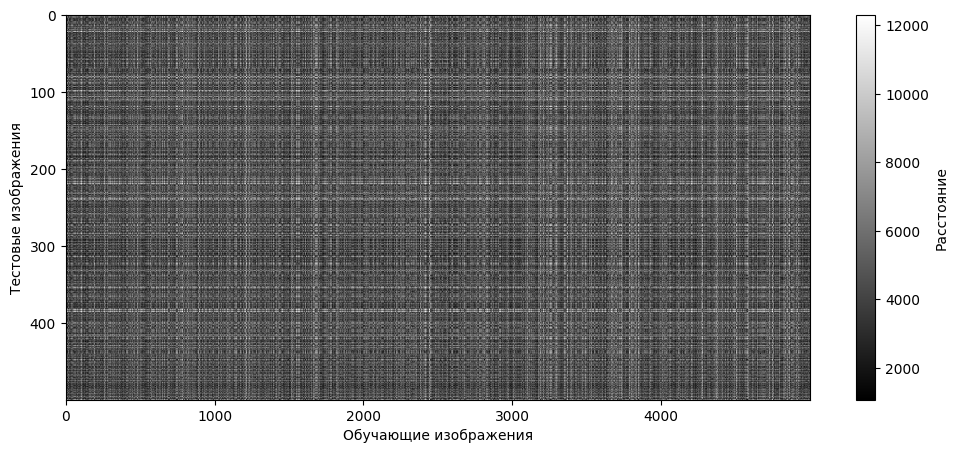

In [10]:
# Матрица расстояний: каждая строка — тестовая картинка, каждый столбец — обучающая; светлее = дальше
plt.figure(figsize=(12, 5))
plt.imshow(dists, interpolation='none', aspect='auto')
plt.xlabel('Обучающие изображения')
plt.ylabel('Тестовые изображения')
plt.colorbar(label='Расстояние')
plt.show()


1.7 Посчитайте долю правильно классифицированных изображений из тестовой выборки.


In [11]:
# Доля правильно классифицированных тестовых картинок при k = 1
num_correct = np.sum(y_test_pred == y_test)
accuracy = num_correct / len(y_test)
print('Правильно: %d из %d, accuracy = %.3f' % (num_correct, len(y_test), accuracy))

Правильно: 137 из 500, accuracy = 0.274


1.8 Постройте график зависимости доли правильно классифицированных изображений от числа соседей, используемых при классификации.

k =   1, accuracy = 0.274
k =   3, accuracy = 0.272
k =   5, accuracy = 0.278
k =   8, accuracy = 0.274
k =  10, accuracy = 0.282
k =  12, accuracy = 0.256
k =  15, accuracy = 0.272
k =  20, accuracy = 0.272
k =  50, accuracy = 0.252
k = 100, accuracy = 0.222


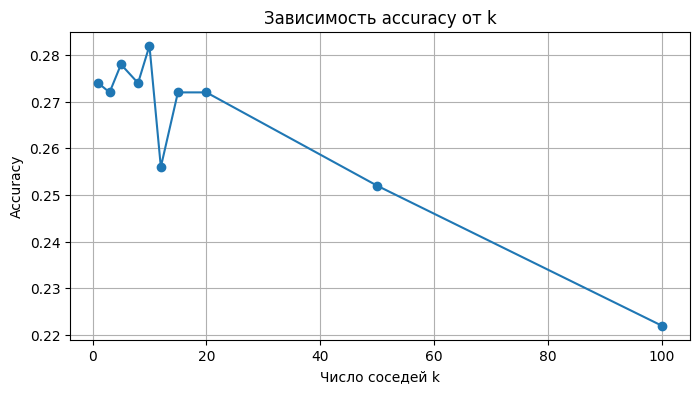

In [12]:
# Accuracy на тестовой выборке для разного числа соседей k
k_values = [1, 3, 5, 8, 10, 12, 15, 20, 50, 100]
test_accuracies = []

for k in k_values:
    pred = classifier.predict_labels(dists, k=k)
    acc = np.mean(pred == y_test)
    test_accuracies.append(acc)
    print('k = %3d, accuracy = %.3f' % (k, acc))

plt.figure(figsize=(8, 4))
plt.plot(k_values, test_accuracies, marker='o')
plt.xlabel('Число соседей k')
plt.ylabel('Accuracy')
plt.title('Зависимость accuracy от k')
plt.grid(True)
plt.show()

1.9 Выберите лучшее значение параметра k на основе кросс-валидации.


k =   1, средняя accuracy = 0.266 ± 0.007
k =   3, средняя accuracy = 0.250 ± 0.010
k =   5, средняя accuracy = 0.273 ± 0.015
k =   8, средняя accuracy = 0.276 ± 0.009
k =  10, средняя accuracy = 0.280 ± 0.010
k =  12, средняя accuracy = 0.279 ± 0.011
k =  15, средняя accuracy = 0.275 ± 0.013
k =  20, средняя accuracy = 0.279 ± 0.005
k =  50, средняя accuracy = 0.274 ± 0.008
k = 100, средняя accuracy = 0.262 ± 0.005

Лучшее k = 10


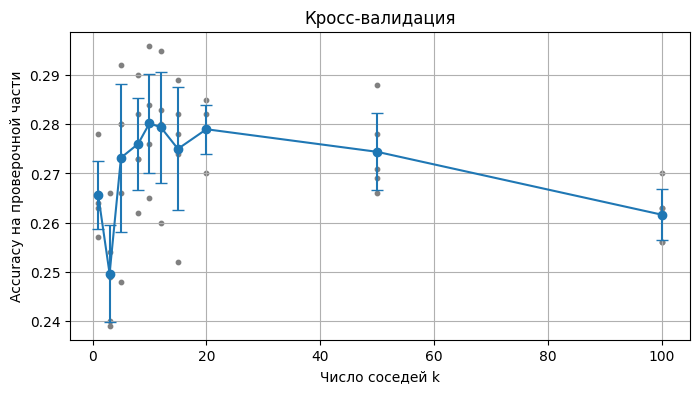

In [13]:
# Кросс-валидация: обучающая выборка делится на 5 частей, каждая по очереди служит проверочной
num_folds = 5
k_choices = [1, 3, 5, 8, 10, 12, 15, 20, 50, 100]

X_train_folds = np.array_split(X_train, num_folds)
y_train_folds = np.array_split(y_train, num_folds)

k_to_accuracies = {k: [] for k in k_choices}

for i in range(num_folds):
    X_tr = np.concatenate(X_train_folds[:i] + X_train_folds[i + 1:])
    y_tr = np.concatenate(y_train_folds[:i] + y_train_folds[i + 1:])
    X_val_fold, y_val_fold = X_train_folds[i], y_train_folds[i]

    cv_classifier = KNearestNeighbor()
    cv_classifier.train(X_tr, y_tr)
    cv_dists = cv_classifier.compute_distances_no_loops(X_val_fold)

    for k in k_choices:
        pred = cv_classifier.predict_labels(cv_dists, k=k)
        k_to_accuracies[k].append(np.mean(pred == y_val_fold))

# Средняя точность и разброс по 5 частям для каждого k
mean_acc = np.array([np.mean(k_to_accuracies[k]) for k in k_choices])
std_acc = np.array([np.std(k_to_accuracies[k]) for k in k_choices])
for k, m, s in zip(k_choices, mean_acc, std_acc):
    print('k = %3d, средняя accuracy = %.3f ± %.3f' % (k, m, s))

best_k = k_choices[np.argmax(mean_acc)]
print('\nЛучшее k =', best_k)

# Точки — результаты на каждой из 5 частей, линия — среднее, вертикальные отрезки — разброс
plt.figure(figsize=(8, 4))
for k in k_choices:
    plt.scatter([k] * num_folds, k_to_accuracies[k], color='gray', s=10)
plt.errorbar(k_choices, mean_acc, yerr=std_acc, marker='o', capsize=4)
plt.xlabel('Число соседей k')
plt.ylabel('Accuracy на проверочной части')
plt.title('Кросс-валидация')
plt.grid(True)
plt.show()


1.10 Переобучите и протестируйте классификатор с использованием выбранного значения k.



In [14]:
# Обучение на всех 5000 картинках и проверка на тестовой выборке с лучшим k
best_classifier = KNearestNeighbor()
best_classifier.train(X_train, y_train)
y_test_pred = best_classifier.predict(X_test, k=best_k)

num_correct = np.sum(y_test_pred == y_test)
accuracy = num_correct / len(y_test)
print('k = %d: правильно %d из %d, accuracy = %.3f' % (best_k, num_correct, len(y_test), accuracy))

k = 10: правильно 141 из 500, accuracy = 0.282


1.11 Сделайте выводы по результатам 1 части задания.

**Выводы по части 1**

1. Реализован классификатор k ближайших соседей с евклидовым расстоянием. Расстояния считаются тремя способами (два цикла, один цикл, без циклов). Варианты без циклов и с одним циклом дают одинаковую матрицу расстояний (разница 0.0). В работе используется вариант без циклов: в нём все расстояния считаются одной матричной операцией.

2. Для ускорения взяты 5000 обучающих и 500 тестовых изображений, каждое представлено вектором из 3072 значений пикселей.

3. На матрице расстояний видны светлые горизонтальные и вертикальные полосы — это изображения, сильно отличающиеся от остальных (например, по яркости или фону). Это показывает, что расстояние по пикселям в большей степени отражает общую яркость и цвет, а не содержание картинки.

4. При k = 1 доля правильных ответов на тестовой выборке составила 0.274. При случайном угадывании она была бы 0.1, так что метод работает, но слабо.

5. На тестовой выборке точность при малых k менялась скачками (от 0.256 до 0.282), а при больших k падала (0.222 при k = 100): в голосовании участвует слишком много непохожих изображений.

6. Кросс-валидация на 5 частях показала лучшее значение k = 10 (средняя точность 0.280 ± 0.010). Значения k от 8 до 20 дают почти одинаковый результат, разница между ними меньше разброса между частями.

7. С k = 10 точность на тестовой выборке составила 0.282, это лучше, чем при k = 1.

8. Главный недостаток метода — низкая точность на «сырых» пикселях и медленная работа: каждое новое изображение нужно сравнить со всеми обучающими.

## 2.  Классификация данных методом опорных векторов (SVM)

2.1 Разделите данные на обучающую, тестовую и валидационную выборки. Преобразуйте каждое изображение в одномерный массив. Выведите размеры выборок.

In [ ]:
np.random.seed(0)

# Загрузка полного набора
X_train, y_train, X_test, y_test = load_CIFAR10('scripts/datasets/cifar-10-batches-py')

num_training = 49000
num_validation = 1000
num_test = 1000

# Валидационная выборка — последние 1000 картинок обучающего набора
X_val = X_train[num_training:num_training + num_validation]
y_val = y_train[num_training:num_training + num_validation]
X_train = X_train[:num_training]
y_train = y_train[:num_training]
X_test = X_test[:num_test]
y_test = y_test[:num_test]

# Каждая картинка превращается в строку из 3072 чисел
X_train = X_train.reshape(X_train.shape[0], -1)
X_val = X_val.reshape(X_val.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

print('Обучающая:     ', X_train.shape, y_train.shape)
print('Валидационная: ', X_val.shape, y_val.shape)
print('Тестовая:      ', X_test.shape, y_test.shape)

Обучающая:      (49000, 3072) (49000,)
Валидационная:  (1000, 3072) (1000,)
Тестовая:       (1000, 3072) (1000,)


2.2 Проведите предварительную обработку данных, путем вычитания среднего изображения, рассчитанного  по обучающей выборке.

2.3 Чтобы далее не учитывать смещение (свободный член b), добавьте дополнитульную размерность к массиву дынных и заполните ее 1.

[130.64189796 135.98173469 132.47391837 130.05569388 135.34804082
 131.75402041 130.96055102 136.14328571 132.47636735 131.48467347]


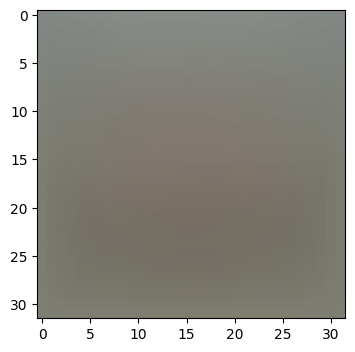

(49000, 3073) (1000, 3073) (1000, 3073)


In [ ]:
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10])
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((32,32,3)).astype('uint8'))
plt.show()

X_train -= mean_image
X_val -= mean_image
X_test -= mean_image

X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])

print(X_train.shape, X_val.shape, X_test.shape)

In [17]:
# Небольшая выборка из 500 обучающих картинок для быстрой проверки функций потерь
num_dev = 500
dev_idx = np.random.choice(X_train.shape[0], num_dev, replace=False)
X_dev = X_train[dev_idx]
y_dev = y_train[dev_idx]
print('X_dev:', X_dev.shape, 'y_dev:', y_dev.shape)

X_dev: (500, 3073) y_dev: (500,)


2.4 Реализуйте loss-функции в scripts/classifiers/linear_svm.py



In [ ]:
%%writefile scripts/classifiers/linear_svm.py
import numpy as np

def svm_loss_naive(W, X, y, reg):
    # Функция потерь SVM и её градиент по весам W, простая версия с циклами
    dW = np.zeros(W.shape)
    num_classes = W.shape[1]
    num_train = X.shape[0]
    loss = 0.0
    for i in range(num_train):
        scores = X[i].dot(W)
        correct_class_score = scores[y[i]]
        for j in range(num_classes):
            if j == y[i]:
                continue
            margin = scores[j] - correct_class_score + 1
            if margin > 0:
                loss += margin
                # Неверный класс j набрал слишком много очков: его веса тянем вниз, веса верного класса вверх
                dW[:, j] += X[i]
                dW[:, y[i]] -= X[i]

    loss /= num_train
    dW /= num_train
    loss += reg * np.sum(W * W)
    dW += 2 * reg * W
    return loss, dW

def svm_loss_vectorized(W, X, y, reg):
    # То же самое без циклов, сразу для всех картинок
    num_train = X.shape[0]
    rows = np.arange(num_train)

    scores = X.dot(W)
    correct_scores = scores[rows, y][:, np.newaxis]
    margins = np.maximum(0, scores - correct_scores + 1)
    margins[rows, y] = 0
    loss = margins.sum() / num_train + reg * np.sum(W * W)

    # 1 там, где неверный класс нарушил запас; у верного класса минус число таких нарушений
    mask = (margins > 0).astype(float)
    mask[rows, y] = -mask.sum(axis=1)
    dW = X.T.dot(mask) / num_train + 2 * reg * W
    return loss, dW

Overwriting scripts/classifiers/linear_svm.py


In [ ]:
%%writefile scripts/classifiers/linear_classifier.py
import numpy as np
from scripts.classifiers.linear_svm import *
from scripts.classifiers.softmax import *

class LinearClassifier(object):
    # Линейный классификатор: очки классов = X · W, обучение стохастическим градиентным спуском

    def __init__(self):
        self.W = None

    def train(self, X, y, learning_rate=1e-3, reg=1e-5, num_iters=100,
              batch_size=200, verbose=False):
        # Обучение весов W; возвращает список значений функции потерь на каждом шаге
        num_train, dim = X.shape
        num_classes = np.max(y) + 1
        if self.W is None:
            self.W = 0.001 * np.random.randn(dim, num_classes)

        loss_history = []
        for it in range(num_iters):
            # Случайная пачка картинок для одного шага
            idx = np.random.choice(num_train, batch_size, replace=True)
            X_batch = X[idx]
            y_batch = y[idx]

            loss, grad = self.loss(X_batch, y_batch, reg)
            loss_history.append(loss)

            # Шаг против градиента
            self.W -= learning_rate * grad

            if verbose and it % 100 == 0:
                print('iteration %d / %d: loss %f' % (it, num_iters, loss))

        return loss_history

    def predict(self, X):
        # Предсказанный класс — тот, у которого больше всего очков
        return np.argmax(X.dot(self.W), axis=1)

    def loss(self, X_batch, y_batch, reg):
        # Функция потерь и градиент; задаётся в классах-наследниках
        pass

class LinearSVM(LinearClassifier):
    # Линейный классификатор с функцией потерь SVM

    def loss(self, X_batch, y_batch, reg):
        return svm_loss_vectorized(self.W, X_batch, y_batch, reg)

class Softmax(LinearClassifier):
    # Линейный классификатор с функцией потерь Softmax

    def loss(self, X_batch, y_batch, reg):
        return softmax_loss_vectorized(self.W, X_batch, y_batch, reg)

Overwriting scripts/classifiers/linear_classifier.py


In [20]:
# Повторная загрузка модулей после записи файлов
import importlib
import scripts.classifiers.linear_svm
import scripts.classifiers.linear_classifier
import scripts.classifiers
importlib.reload(scripts.classifiers.linear_svm)
importlib.reload(scripts.classifiers.linear_classifier)
importlib.reload(scripts.classifiers)

from scripts.classifiers.linear_svm import svm_loss_vectorized

In [21]:

from scripts.classifiers.linear_svm import svm_loss_naive
import time

W = np.random.randn(3073, 10) * 0.0001

loss, grad = svm_loss_naive(W, X_dev, y_dev, 0.000005)
print('loss: %f' % (loss, ))

loss: 9.286185



2.5 Убедитесь, что вы верно реализовали расчет градиента, сравнив с реализацией численными методами (код приведен ниже).

In [ ]:
loss, grad = svm_loss_naive(W, X_dev, y_dev, 0.0)

from scripts.gradient_check import grad_check_sparse
f = lambda w: svm_loss_naive(w, X_dev, y_dev, 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad)

loss, grad = svm_loss_naive(W, X_dev, y_dev, 5e1)
f = lambda w: svm_loss_naive(w, X_dev, y_dev, 5e1)[0]
grad_numerical = grad_check_sparse(f, W, grad)

numerical: 5.390542 analytic: 5.381382, relative error: 8.503403e-04
numerical: 16.176884 analytic: 16.166961, relative error: 3.067771e-04
numerical: 32.813017 analytic: 32.819513, relative error: 9.897507e-05
numerical: 0.925817 analytic: 0.925817, relative error: 3.855684e-10
numerical: -27.581002 analytic: -27.581002, relative error: 6.960708e-12
numerical: -9.324129 analytic: -9.324129, relative error: 4.621179e-11
numerical: 20.949095 analytic: 20.949095, relative error: 8.361618e-12
numerical: 20.625007 analytic: 20.625007, relative error: 1.494301e-11
numerical: -11.540702 analytic: -11.540702, relative error: 7.479408e-12
numerical: -51.115276 analytic: -51.115276, relative error: 3.867617e-12
numerical: -10.608767 analytic: -10.608767, relative error: 2.578051e-11
numerical: 9.654271 analytic: 9.654271, relative error: 1.502795e-11
numerical: -5.908048 analytic: -5.908048, relative error: 5.417483e-11
numerical: 8.585347 analytic: 8.585347, relative error: 1.202536e-12
numeri

2.6 Сравните svm_loss_naive и svm_loss_vectorized реализации

In [23]:
tic = time.time()
_, grad_naive = svm_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Naive loss and gradient: computed in %fs' % (toc - tic))

tic = time.time()
_, grad_vectorized = svm_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Vectorized loss and gradient: computed in %fs' % (toc - tic))

difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print('difference: %f' % difference)

Naive loss and gradient: computed in 0.065717s
Vectorized loss and gradient: computed in 0.005302s
difference: 0.000000


2.7 Реализуйте стохастический градиентный спуск в /classifiers/linear_classifier.py . Реализуйте методы train() и predict() и запустите следующий код

In [24]:
from scripts.classifiers import LinearSVM
svm = LinearSVM()
tic = time.time()
loss_hist = svm.train(X_train, y_train, learning_rate=1e-7, reg=2.5e4,
                      num_iters=1500, verbose=True)
toc = time.time()
print('That took %fs' % (toc - tic))

iteration 0 / 1500: loss 793.822270
iteration 100 / 1500: loss 288.520456
iteration 200 / 1500: loss 108.197115
iteration 300 / 1500: loss 42.336277
iteration 400 / 1500: loss 18.764049
iteration 500 / 1500: loss 9.692809
iteration 600 / 1500: loss 6.673710
iteration 700 / 1500: loss 5.862692
iteration 800 / 1500: loss 5.763091
iteration 900 / 1500: loss 5.534589
iteration 1000 / 1500: loss 5.564984
iteration 1100 / 1500: loss 5.160274
iteration 1200 / 1500: loss 5.104413
iteration 1300 / 1500: loss 5.107830
iteration 1400 / 1500: loss 5.314120
That took 6.668207s


In [25]:
y_train_pred = svm.predict(X_train)
print('training accuracy: %f' % (np.mean(y_train == y_train_pred), ))
y_val_pred = svm.predict(X_val)
print('validation accuracy: %f' % (np.mean(y_val == y_val_pred), ))

training accuracy: 0.376408
validation accuracy: 0.396000


2.8 С помощью кросс-валидации выберите значения параметров скорости обучения и регуляризации. В кросс-валидации используйте обучающую и валидационную выборки. Оцените accuracy на тестовой выборке.

In [26]:
learning_rates = [1e-7, 5e-5]
regularization_strengths = [2.5e4, 5e4]

In [27]:
# Перебор всех пар (скорость обучения, регуляризация): обучение на train, оценка на val
lr_grid = sorted(set(learning_rates + [5e-8, 2e-7, 5e-7]))
reg_grid = sorted(set(regularization_strengths + [1e4]))

results = {}
best_val = -1
best_svm = None

for lr in lr_grid:
    for reg in reg_grid:
        svm = LinearSVM()
        # Без предупреждений о переполнении
        with np.errstate(over='ignore', invalid='ignore'):
            svm.train(X_train, y_train, learning_rate=lr, reg=reg, num_iters=1500)
            train_acc = np.mean(svm.predict(X_train) == y_train)
            val_acc = np.mean(svm.predict(X_val) == y_val)
        results[(lr, reg)] = (train_acc, val_acc)
        print('lr = %.0e, reg = %.1e: train = %.3f, val = %.3f' % (lr, reg, train_acc, val_acc))
        if val_acc > best_val:
            best_val, best_svm, best_lr, best_reg = val_acc, svm, lr, reg

print('\nЛучшие параметры: lr = %.0e, reg = %.1e, val accuracy = %.3f' % (best_lr, best_reg, best_val))

test_acc = np.mean(best_svm.predict(X_test) == y_test)
print('Accuracy на тестовой выборке: %.3f' % test_acc)

lr = 5e-08, reg = 1.0e+04: train = 0.354, val = 0.369
lr = 5e-08, reg = 2.5e+04: train = 0.373, val = 0.385
lr = 5e-08, reg = 5.0e+04: train = 0.361, val = 0.366
lr = 1e-07, reg = 1.0e+04: train = 0.374, val = 0.387
lr = 1e-07, reg = 2.5e+04: train = 0.371, val = 0.376
lr = 1e-07, reg = 5.0e+04: train = 0.345, val = 0.351
lr = 2e-07, reg = 1.0e+04: train = 0.374, val = 0.369
lr = 2e-07, reg = 2.5e+04: train = 0.361, val = 0.368
lr = 2e-07, reg = 5.0e+04: train = 0.352, val = 0.379
lr = 5e-07, reg = 1.0e+04: train = 0.356, val = 0.372
lr = 5e-07, reg = 2.5e+04: train = 0.346, val = 0.359
lr = 5e-07, reg = 5.0e+04: train = 0.294, val = 0.310
lr = 5e-05, reg = 1.0e+04: train = 0.168, val = 0.157
lr = 5e-05, reg = 2.5e+04: train = 0.046, val = 0.056
lr = 5e-05, reg = 5.0e+04: train = 0.100, val = 0.087

Лучшие параметры: lr = 1e-07, reg = 1.0e+04, val accuracy = 0.387
Accuracy на тестовой выборке: 0.363


2.9 Сделайте выводы по второй части задания

**Выводы по части 2**

1. Реализован линейный классификатор с функцией потерь SVM: две версии функции потерь и градиента (с циклами и векторная) и обучение стохастическим градиентным спуском пачками по 200 изображений.

2. Перед обучением из всех изображений вычтено среднее изображение обучающей выборки, а к каждому вектору добавлена единица, чтобы смещение учитывалось как обычный вес.

3. Правильность градиента подтверждена численной проверкой: в 17 точках из 20 относительная ошибка порядка 1e-10 и меньше. В трёх точках ошибка около 1e-4: функция потерь SVM имеет изломы (там, где запас становится равен нулю), и если численная проверка попадает рядом с изломом, приближённое значение производной немного отличается от точного.

4. Векторная версия даёт тот же результат, что и версия с циклами (разница 0), но работает примерно в 12 раз быстрее (0.005 с против 0.066 с на 500 изображениях). На полной выборке разница была бы ещё заметнее.

5. При обучении функция потерь снизилась с ~794 до ~5 за 1500 шагов. Точность на обучающей и валидационной выборках близка (0.376 и 0.396), то есть модель не переобучилась.

6. Подбор параметров по валидационной выборке показал лучшую комбинацию: скорость обучения 1e-7 и регуляризация 1e4 (точность на валидации 0.387). Слишком большая скорость обучения (5e-5) приводит к расхождению обучения и точности на уровне случайного угадывания или ниже.

7. Точность на тестовой выборке составила 0.363. Это заметно лучше, чем у метода k ближайших соседей (0.282). Кроме того, SVM классифицирует новое изображение намного быстрее: нужно только одно умножение на матрицу весов, а не сравнение со всеми обучающими изображениями.

8. Ограничение метода — он линейный: на каждый класс приходится по одному «шаблону», поэтому точность на сырых пикселях остаётся невысокой.